In [2]:
# This imports a tool that converts text documents into numerical TF-IDF vectors.
from sklearn.feature_extraction.text import TfidfVectorizer

# This imports a function that compares numerical vectors.
from sklearn.metrics.pairwise import cosine_similarity

# Your TF-IDF vectors may contain dozens or hundreds of dimensions because each unique vocabulary word contributes a dimension. But a 3D graph can display only three coordinates. PCA reduces the dimentions of a vector.
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

# Step 1: Create documents with related words and concepts
documents = [
    "dogs are friendly animals and make great pets",
    "cats are friendly animals and make wonderful pets",
    "dogs and cats are popular household pets",
    "kings rule kingdoms and queens rule alongside kings",
    "queens and kings are members of royal families",
    "kingdoms are ruled by kings or queens",
    "cars are road vehicles used for transportation",
    "buses are public vehicles used for transportation",
    "cars and buses are common types of vehicles"
]

# Step 2: Convert documents into TF-IDF vectors
vectorizer = TfidfVectorizer()
embeddings = vectorizer.fit_transform(documents).toarray()

# Suppose the vocabulary has V unique words and there are 9 documents. Then array has shape 9xV, each row is one document, and each column corresponds to one vocabulary word.

print("Shape of embeddings:", embeddings.shape)
print("\nTF-IDF vector for the first document:")
print(embeddings[0])

Shape of embeddings: (9, 34)

TF-IDF vector for the first document:
[0.         0.23626092 0.38381534 0.19249526 0.         0.
 0.         0.         0.         0.38381534 0.         0.
 0.38381534 0.45442589 0.         0.         0.         0.38381534
 0.         0.         0.         0.33371636 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.        ]


In [ ]:
#  Step 3: Calculate cosine similarity between documents
#  similarity matrix: You have nine documents, so comparing every document with every other document produces a 9x9 matrix.
similarity_matrix = cosine_similarity(embeddings)

print("\nDocument similarities:")
for i, document in enumerate(documents):
    print(f"\nDocument {i + 1}: {document}")
    for j, other_document in enumerate(documents):
        print(f"  Document {j + 1}: {similarity_matrix[i][j]:.3f}")




Document similarities:

Document 1: dogs are friendly animals and make great pets
  Document 1: 1.000
  Document 2: 0.646
  Document 3: 0.368
  Document 4: 0.042
  Document 5: 0.089
  Document 6: 0.037
  Document 7: 0.038
  Document 8: 0.038
  Document 9: 0.090

Document 2: cats are friendly animals and make wonderful pets
  Document 1: 0.646
  Document 2: 1.000
  Document 3: 0.368
  Document 4: 0.042
  Document 5: 0.089
  Document 6: 0.037
  Document 7: 0.038
  Document 8: 0.038
  Document 9: 0.090

Document 3: dogs and cats are popular household pets
  Document 1: 0.368
  Document 2: 0.368
  Document 3: 1.000
  Document 4: 0.044
  Document 5: 0.093
  Document 6: 0.038
  Document 7: 0.040
  Document 8: 0.040
  Document 9: 0.095

Document 4: kings rule kingdoms and queens rule alongside kings
  Document 1: 0.042
  Document 2: 0.042
  Document 3: 0.044
  Document 4: 1.000
  Document 5: 0.280
  Document 6: 0.355
  Document 7: 0.000
  Document 8: 0.000
  Document 9: 0.041

Document 5: qu

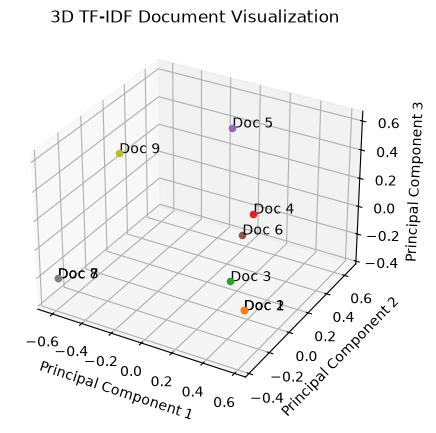

In [ ]:
# Step 4: Reduce the vectors to 3 dimensions using PCA
pca = PCA(n_components=3)
reduced_3d = pca.fit_transform(embeddings)

# Step 5: Visualize the documents in 3D

# This creates a Matplotlib figure, which is the overall canvas on which your graph will be drawn. Think of fig as the sheet of paper containing the visualization.
fig = plt.figure()

# fig.add_subplot(...) adds a plotting area to the figure.
# projection="3d" tells Matplotlib to use a three-dimensional coordinate system.
ax = fig.add_subplot(projection="3d")

for i, document in enumerate(documents):

    # reduced_3d has nine rows and three columns.
    x, y, z = reduced_3d[i]

    # This draws a point at the coordinates (x, y, z).
    ax.scatter(x, y, z)

    # This adds a text label at the same coordinates as the point.
    ax.text(x, y, z, f"Doc {i + 1}")

ax.set_title("3D TF-IDF Document Visualization")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
plt.show()

In [ ]:

import gensim.downloader as api
import numpy as np
from sklearn.manifold import TSNE


# Step 1: Define the words we want to compare
words = [
    "king", "queen", "man", "woman",
    "dog", "cat", "car", "bus"
]


# Step 2: Load the pretrained GloVe model

# GloVe stands for Global Vectors for Word Representation. GloVe generates word embedding vectors that capture semantic relationships between words based on their context.
# The intuition is that words appearing in similar contexts tend to have related vector representations.
# For example, king and queen can have related vectors because they appear in overlapping contexts, such as royalty, kingdoms, and ruling.
# The 50 in the model name means each word is represented by 50 numerical values. So this model stores a 50-dimensional vector for each word in its vocabulary.
model = api.load("glove-wiki-gigaword-50")


# Step 3: Get the embedding vector for each word
embeddings = []

for word in words:
    # This looks up the pretrained vector for the current word.
    vector = model[word]
    embeddings.append(vector)


# Step 4: Convert the list of vectors into a NumPy array
embeddings_array = np.array(embeddings)

# Since there are eight words and each vector has 50 values, the shape is: 8x50
print("Embedding matrix shape:", embeddings_array.shape)

Embedding matrix shape: (8, 50)


In [16]:
# Step 5: Calculate cosine similarity between all words

# A high cosine similarity often indicates related usage or contexts
similarity_matrix = cosine_similarity(embeddings_array)


# Step 6: Print the similarity matrix using nested loops
print("\n----- Printing Similarity Matrix -----")

for i,word in enumerate(words):
    print(f"\n{word}:")
    for j,other_word in enumerate(words):
        similarity = similarity_matrix[i][j]
        print(f"  {other_word}: {similarity:.3f}")


----- Printing Similarity Matrix -----

king:
  king: 1.000
  queen: 0.784
  man: 0.531
  woman: 0.411
  dog: 0.340
  cat: 0.386
  car: 0.263
  bus: 0.212

queen:
  king: 0.784
  queen: 1.000
  man: 0.537
  woman: 0.600
  dog: 0.431
  cat: 0.474
  car: 0.288
  bus: 0.291

man:
  king: 0.531
  queen: 0.537
  man: 1.000
  woman: 0.886
  dog: 0.712
  cat: 0.624
  car: 0.580
  bus: 0.443

woman:
  king: 0.411
  queen: 0.600
  man: 0.886
  woman: 1.000
  dog: 0.661
  cat: 0.586
  car: 0.501
  bus: 0.427

dog:
  king: 0.340
  queen: 0.431
  man: 0.712
  woman: 0.661
  dog: 1.000
  cat: 0.922
  car: 0.464
  bus: 0.406

cat:
  king: 0.386
  queen: 0.474
  man: 0.624
  woman: 0.586
  dog: 0.922
  cat: 1.000
  car: 0.364
  bus: 0.307

car:
  king: 0.263
  queen: 0.288
  man: 0.580
  woman: 0.501
  dog: 0.464
  cat: 0.364
  car: 1.000
  bus: 0.821

bus:
  king: 0.212
  queen: 0.291
  man: 0.443
  woman: 0.427
  dog: 0.406
  cat: 0.307
  car: 0.821
  bus: 1.000



Reduced matrix shape: (8, 3)


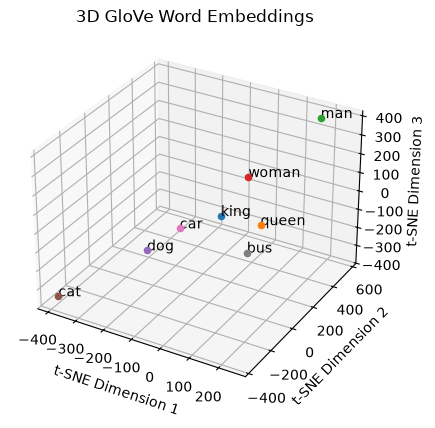

In [ ]:
# Step 7: Reduce the embeddings to 3 dimensions using t-SNE

# n_components=3: Your original vectors have 50 dimensions. After t-SNE, each word gets three coordinates:
tsne = TSNE(
    n_components=3,
    perplexity=3
)

# fit_transform() returns the transformed coordinates.
reduced = tsne.fit_transform(embeddings_array)
print("\nReduced matrix shape:", reduced.shape)


# Step 8: Create a 3D plot
fig = plt.figure()
ax = fig.add_subplot(projection="3d")


# Step 9: Plot and label every word
for i, word in enumerate(words):
    x,y,z = reduced[i]
    ax.scatter(x, y, z)
    ax.text(x, y, z, words[i])


# Step 10: Add graph labels and display it
ax.set_title("3D GloVe Word Embeddings")
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.set_zlabel("t-SNE Dimension 3")


plt.show()
